# Notebook 03: Time-Series Analysis & Holiday Dynamics
**Project:** Walmart Store Sales Forecasting & Business Intelligence System  
**Phase:** Phase 2 — Exploratory Data Analysis & Time-Series Analysis  
**Author:** Lead Data Scientist & Machine Learning Engineer  

---
### Objectives
1. Analyze aggregate weekly sales trajectories and identify annual cyclical peaks.
2. Investigate year-over-year seasonality overlays aligned by ISO week numbers.
3. Compare trajectories across Store Types (A, B, C) and retail product categories.
4. Conduct deep-dive holiday impact analysis (Super Bowl, Labor Day, Thanksgiving, Christmas).
5. Uncover the retail phenomenon: Pre-Christmas Week 51 Surge vs Christmas Week 52.
6. Evaluate promotional markdowns, macroeconomic features, and the test-period blackout.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sys.path.append(os.path.abspath(".."))
from src.data_loader import load_processed_data

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style="whitegrid", palette="muted")
train, test = load_processed_data()
print("Data loaded successfully.")


2026-11-22 15:10:29,770 [INFO] Loading processed datasets from Parquet: E:\MCA projects\Demand-Forecasting\walmart-recruiting-store-sales-forecasting\data\processed


Data loaded successfully.


## 1. Aggregate Weekly Sales Trajectory

Total Weeks: 143
Peak Week:  2010-12-24 ($80,931,415.60)
Trough Week: 2011-01-28 ($39,599,852.99)


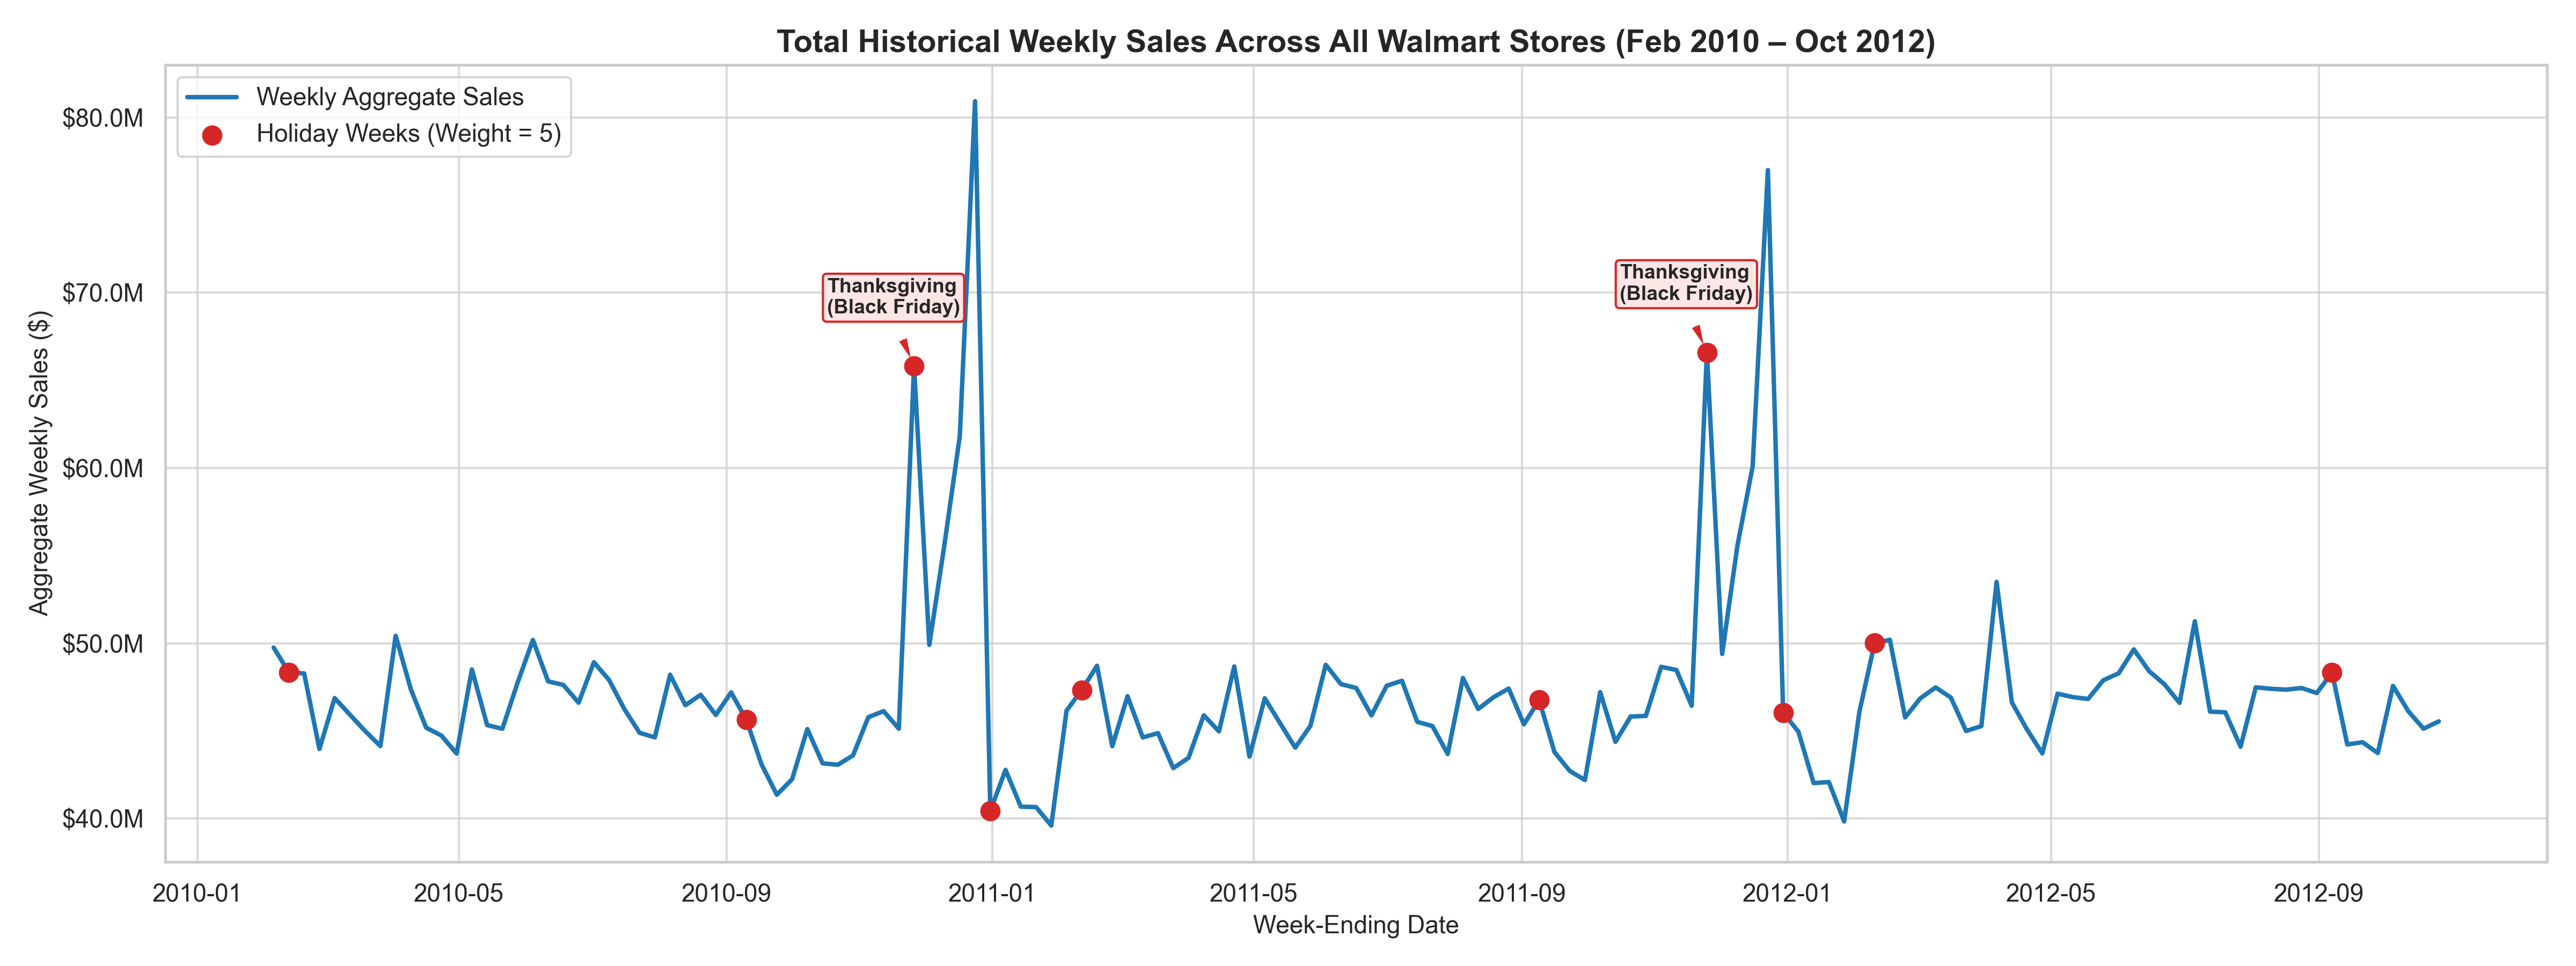

In [2]:
agg_sales = train.groupby('Date')['Weekly_Sales'].sum().reset_index()
print(f"Total Weeks: {len(agg_sales)}")
print(f"Peak Week:  {agg_sales.loc[agg_sales['Weekly_Sales'].idxmax()]['Date'].strftime('%Y-%m-%d')} (${agg_sales['Weekly_Sales'].max():,.2f})")
print(f"Trough Week: {agg_sales.loc[agg_sales['Weekly_Sales'].idxmin()]['Date'].strftime('%Y-%m-%d')} (${agg_sales['Weekly_Sales'].min():,.2f})")

display(Image(filename=os.path.join("..", "outputs", "figures", "fig08_aggregate_weekly_sales_trend.png")))


## 2. Year-over-Year Cyclical Seasonality

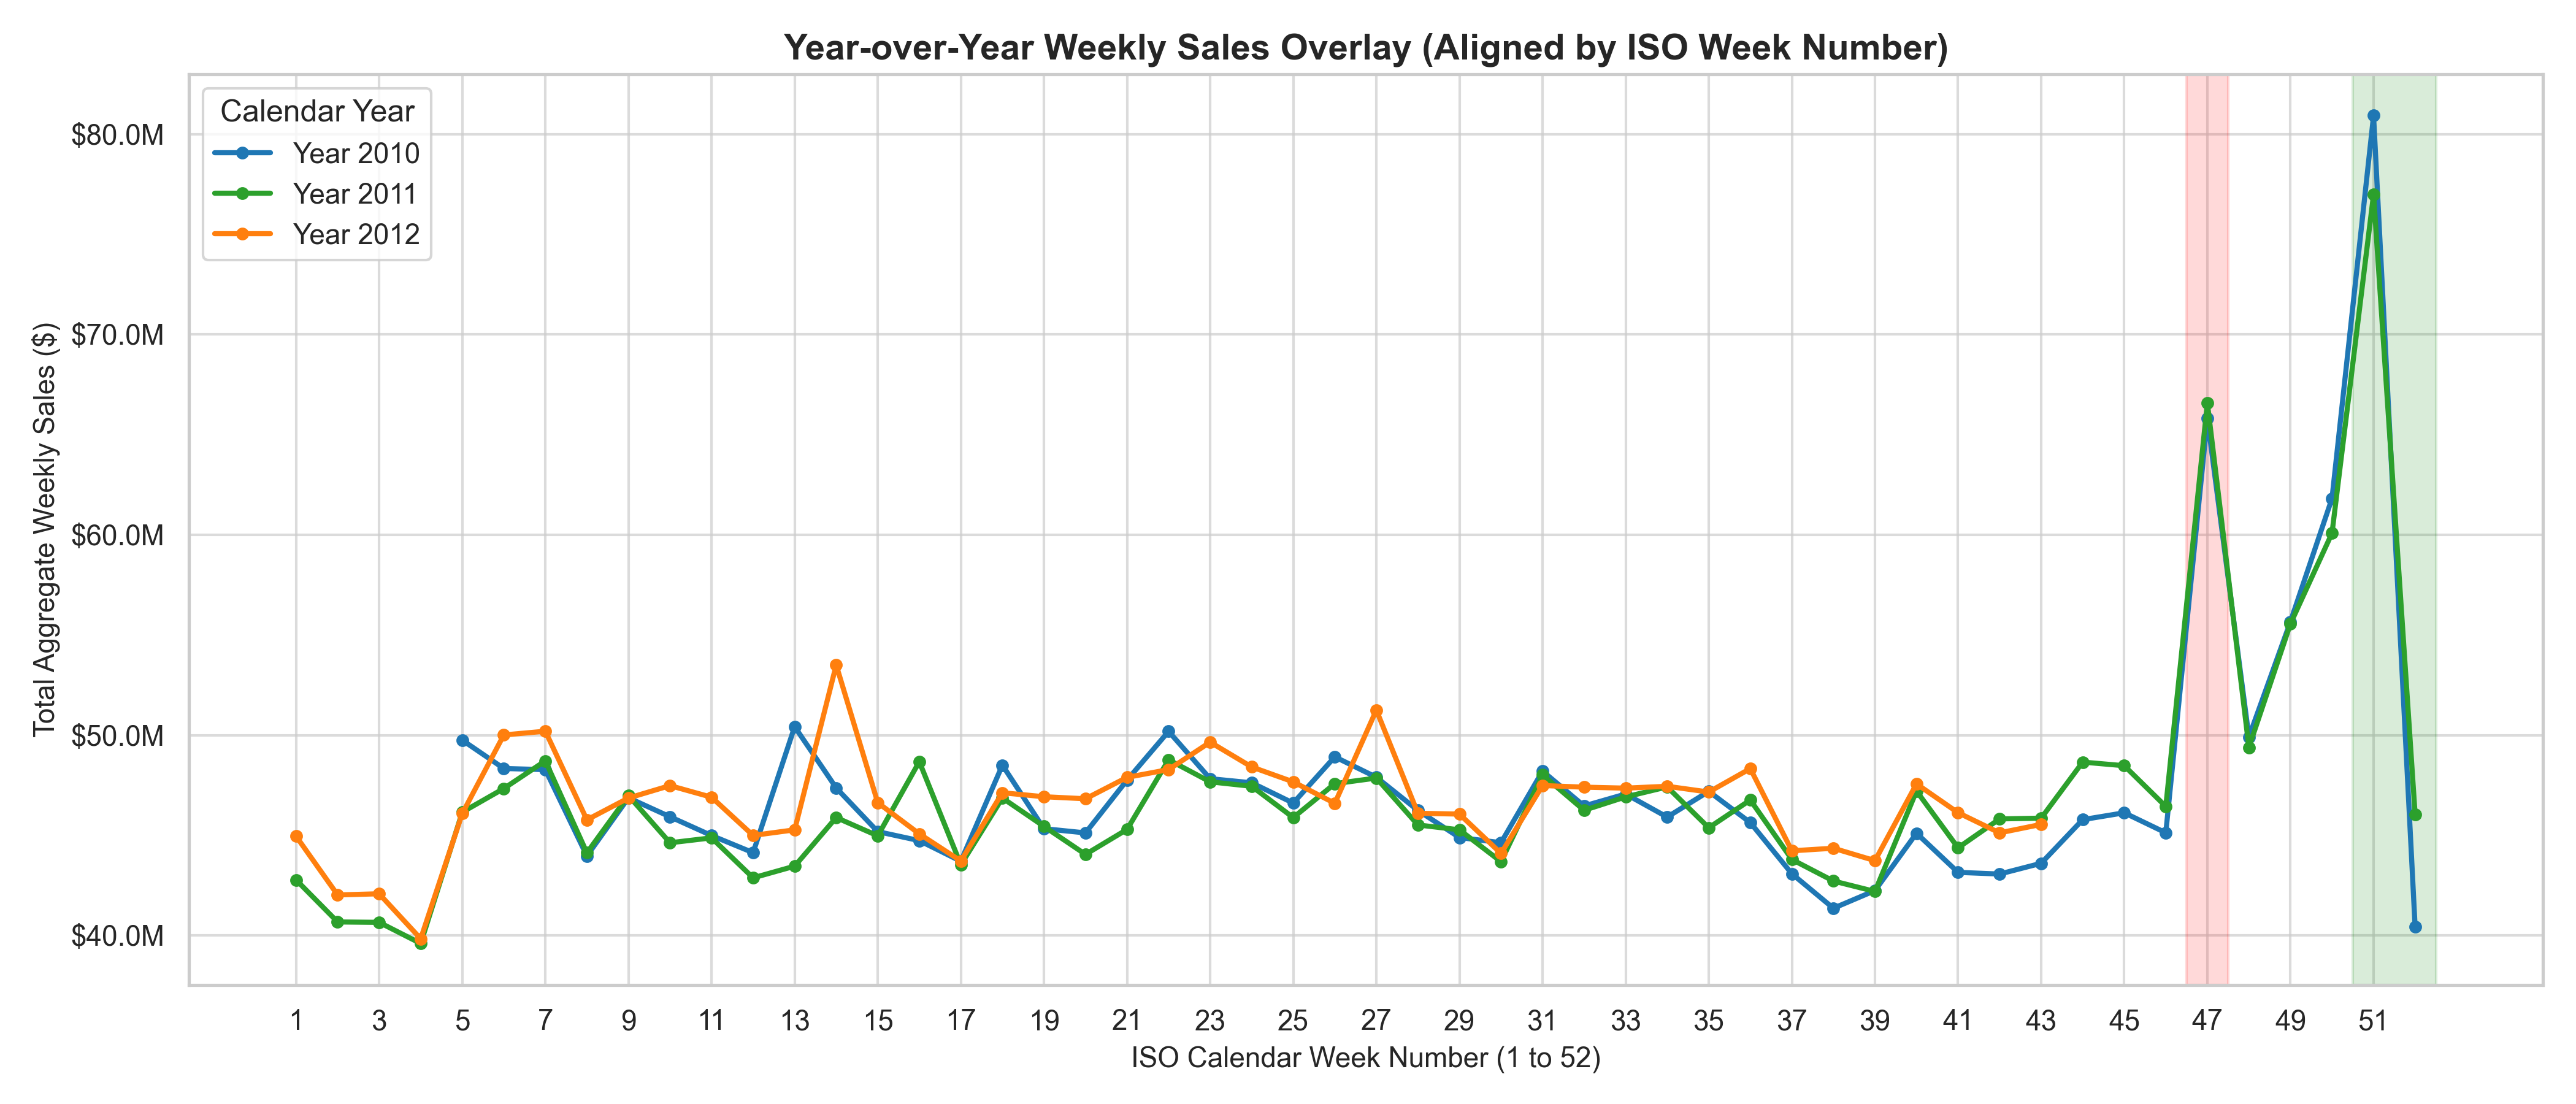

In [3]:
display(Image(filename=os.path.join("..", "outputs", "figures", "fig09_yoy_weekly_sales_overlay.png")))


## 3. Store Type & Department Trajectories

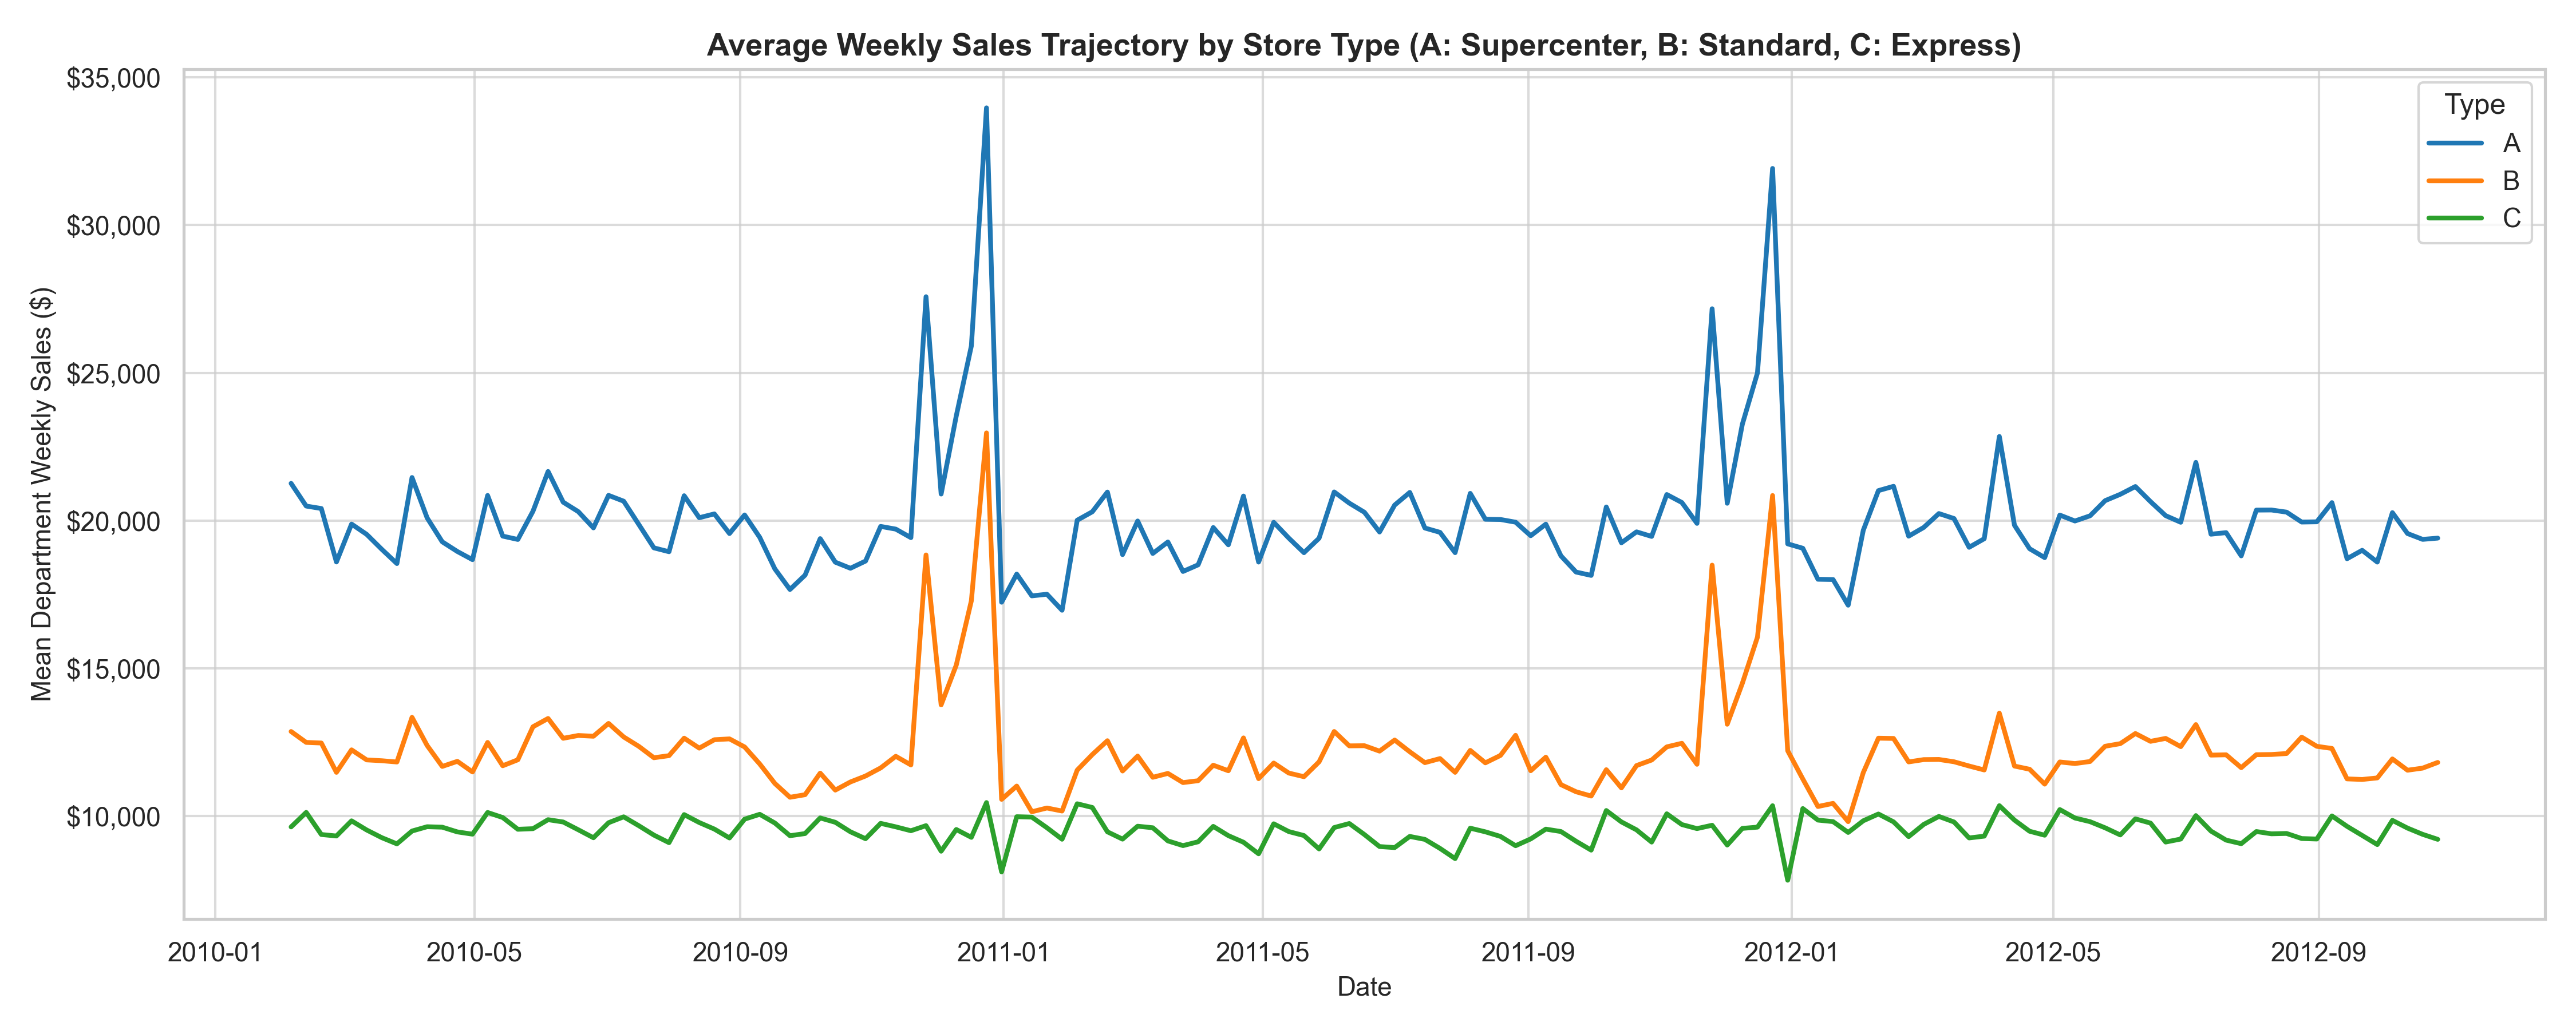

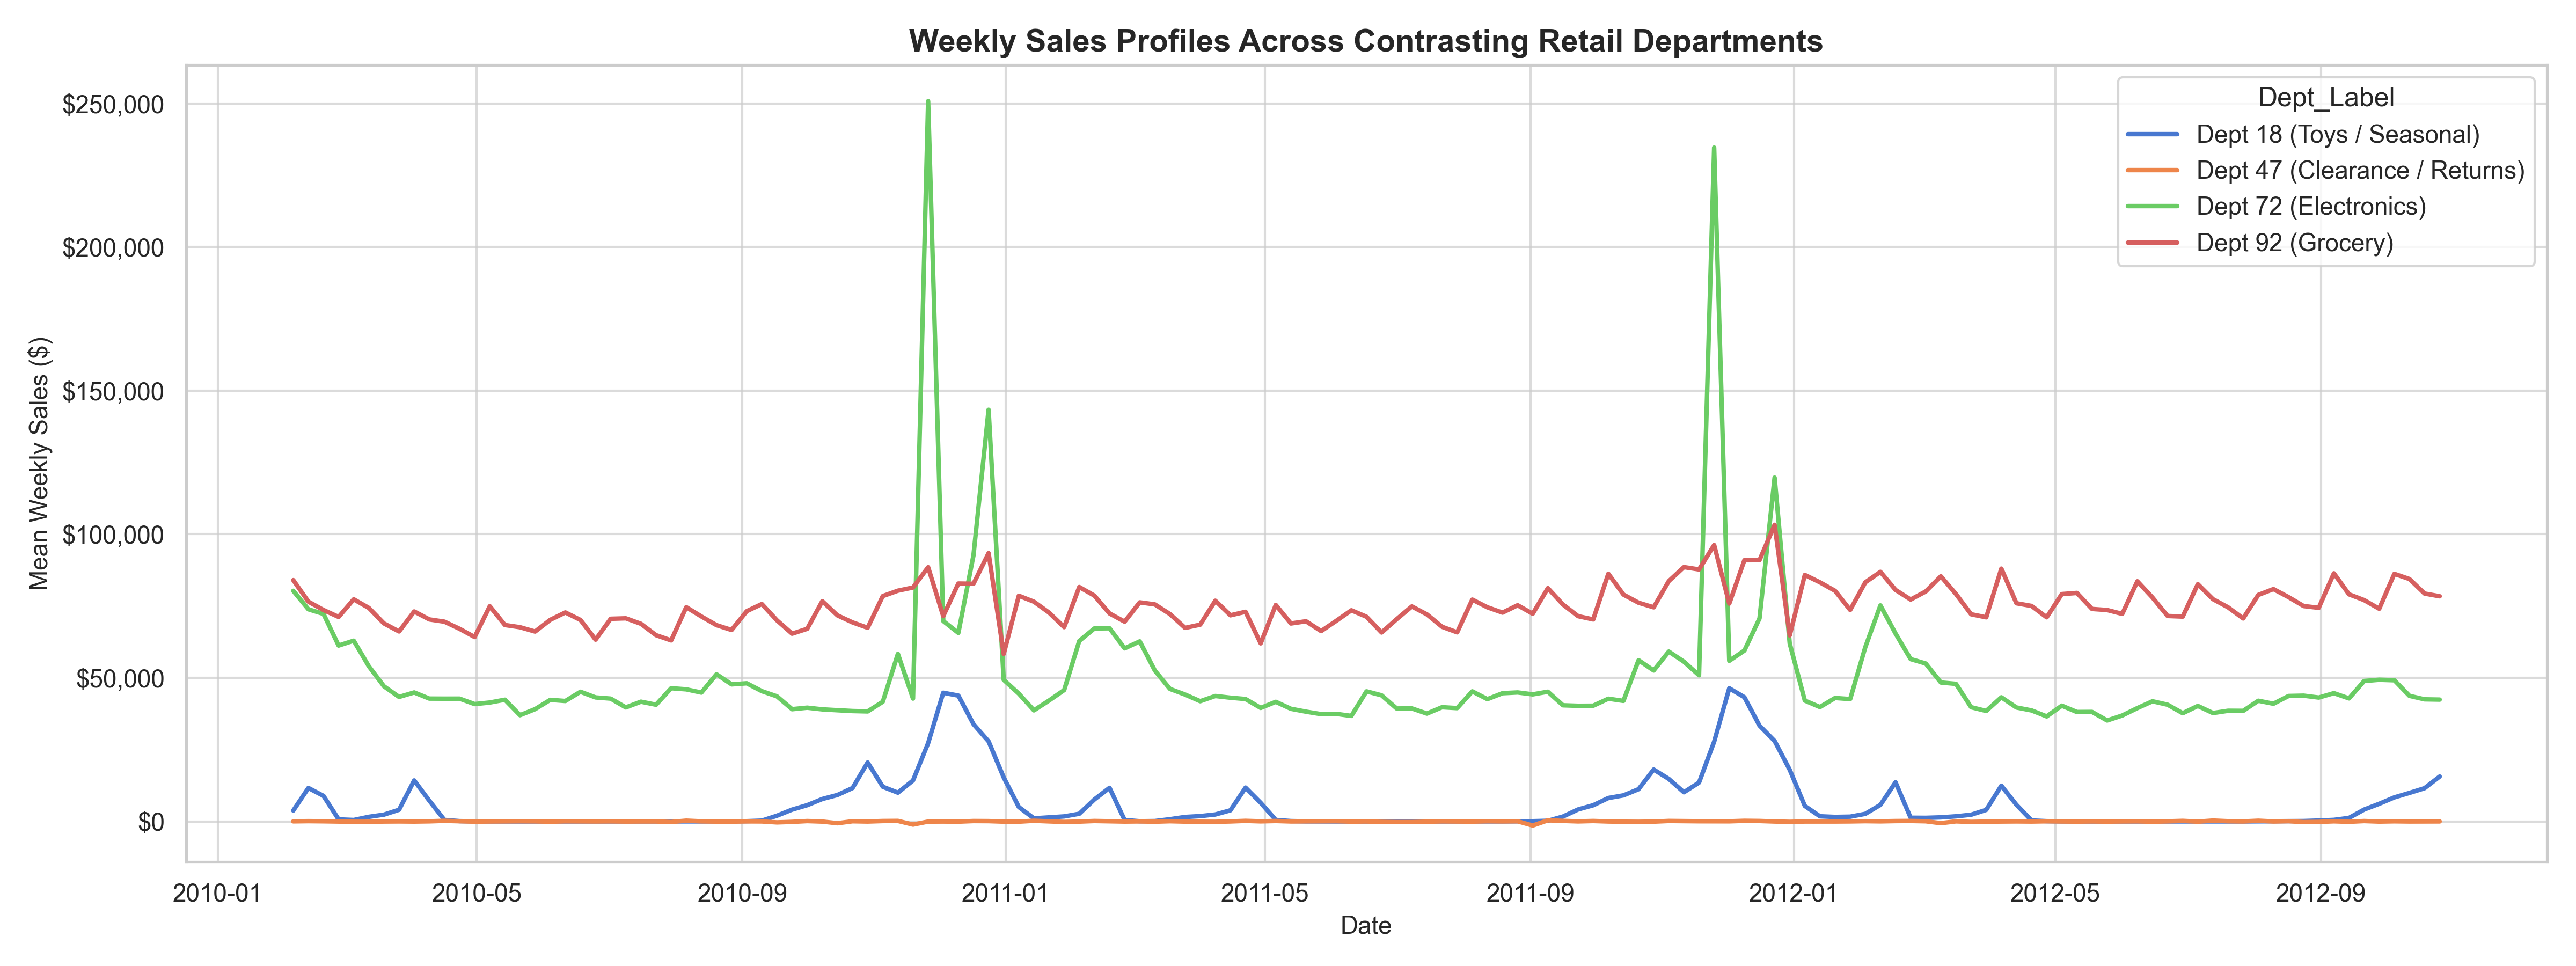

In [4]:
display(Image(filename=os.path.join("..", "outputs", "figures", "fig10_store_type_trends_comparison.png")))
display(Image(filename=os.path.join("..", "outputs", "figures", "fig11_department_seasonality_comparison.png")))


## 4. Holiday Uplift & WMAE Alignment

Comparison of Holiday vs Non-Holiday Weekly Sales:
   IsHoliday   count          mean   median           std           sum  \
0      False  391909  15901.445069  7589.95  22330.747450  6.231919e+09   
1       True   29661  17035.823187  7947.74  27222.000409  5.052996e+08   

   Mean_Uplift_Pct  
0         0.000000  
1         7.133805  


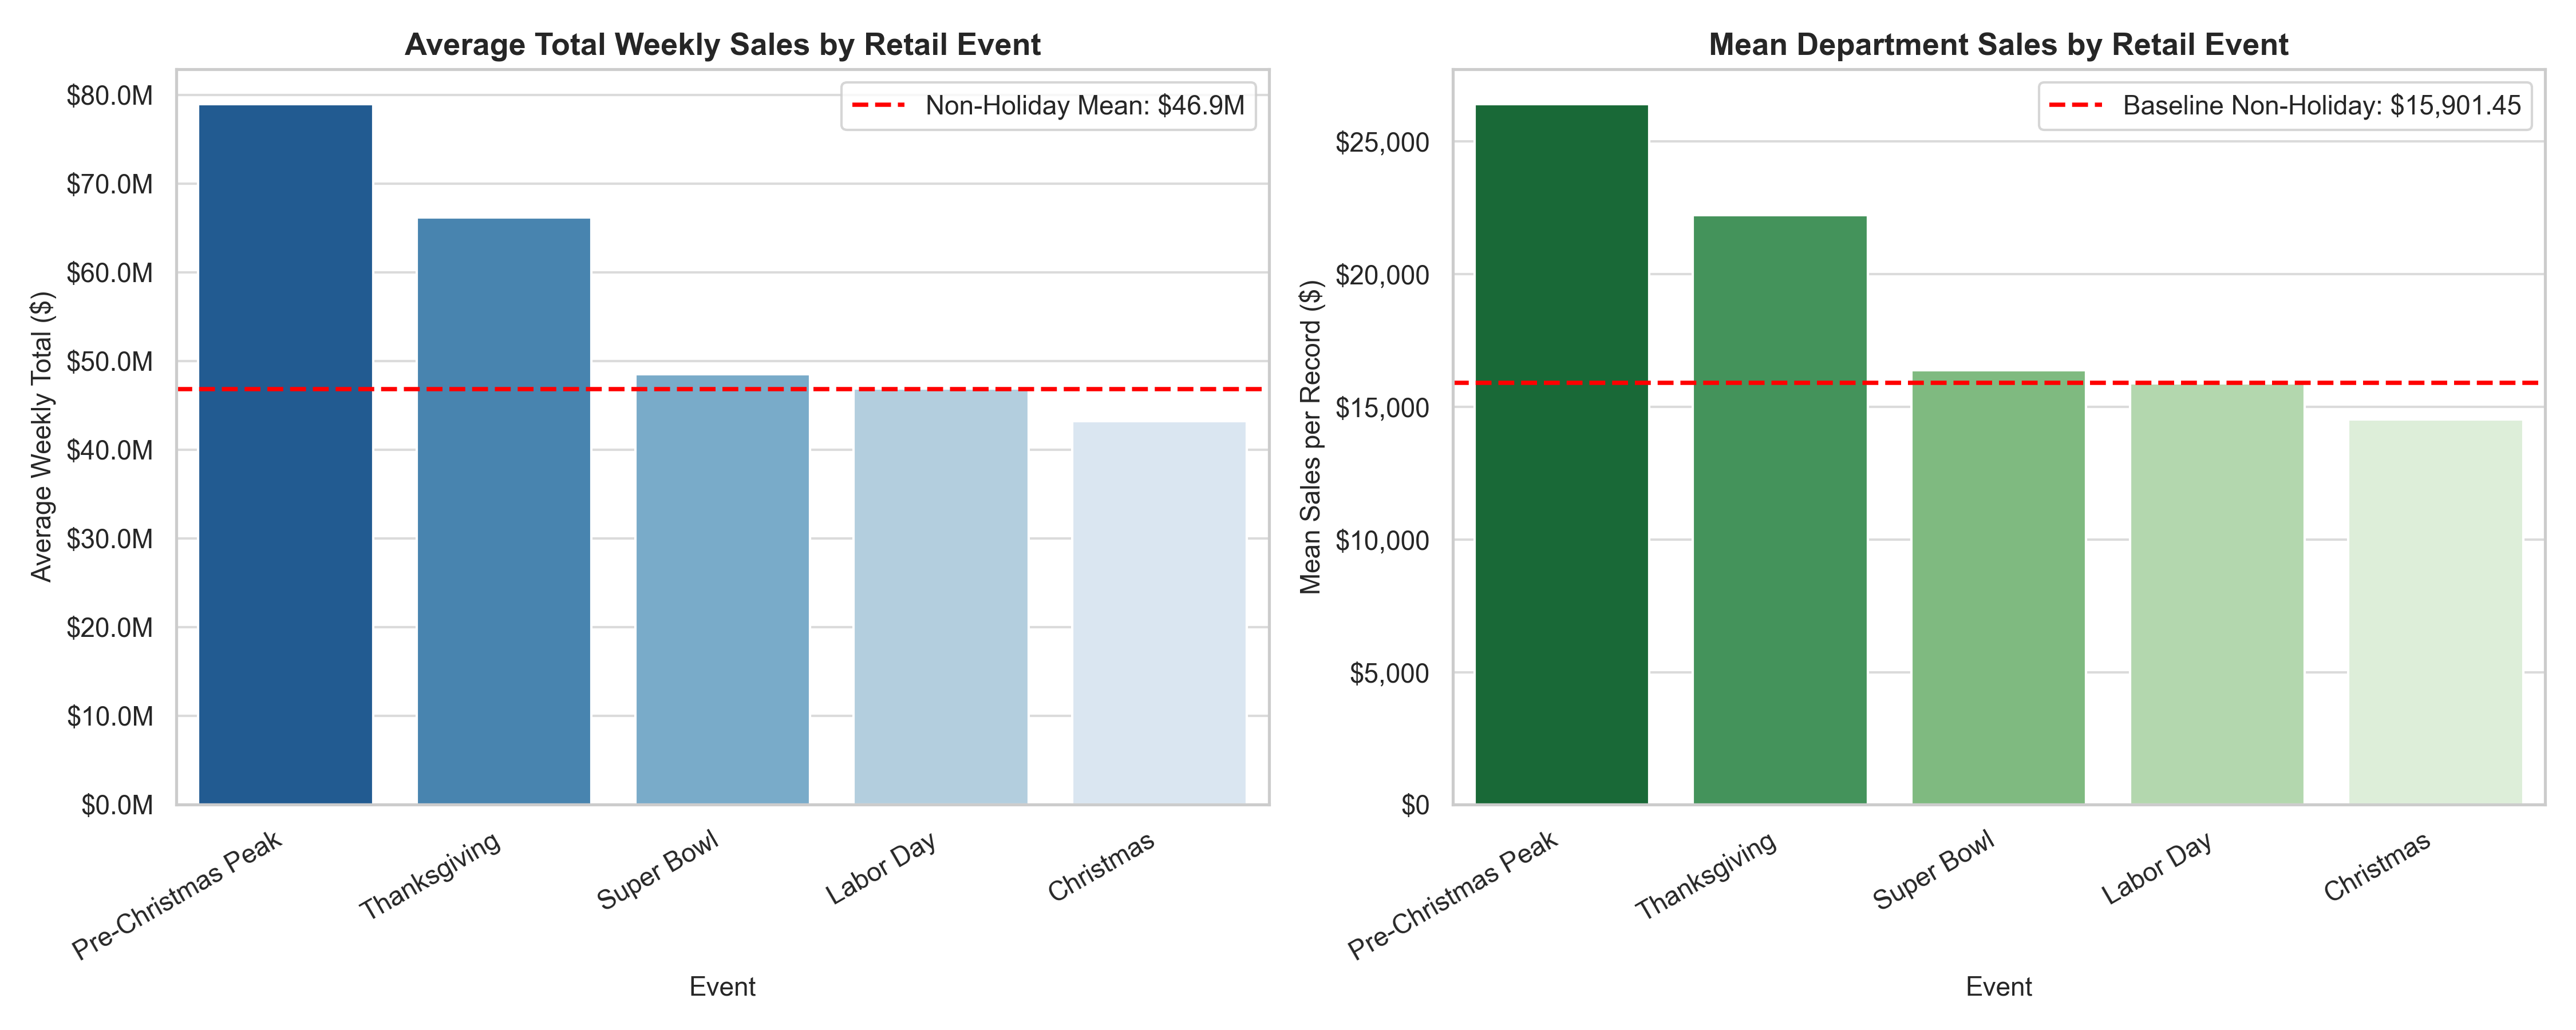

In [5]:
hol_comp = train.groupby('IsHoliday')['Weekly_Sales'].agg(['count', 'mean', 'median', 'std', 'sum']).reset_index()
hol_comp['Mean_Uplift_Pct'] = (hol_comp['mean'] - hol_comp.loc[0, 'mean']) / hol_comp.loc[0, 'mean'] * 100
print("Comparison of Holiday vs Non-Holiday Weekly Sales:")
print(hol_comp)

display(Image(filename=os.path.join("..", "outputs", "figures", "fig12_holiday_sales_uplift_comparison.png")))


## 5. The Pre-Christmas Week Effect (Week 51 vs Week 52)

        Date  Weekly_Sales  IsHoliday
0 2010-12-17   61820799.85      False
1 2010-12-24   80931415.60      False
2 2010-12-31   40432519.00       True
3 2011-12-16   60085695.94      False
4 2011-12-23   76998241.31      False
5 2011-12-30   46042461.04       True


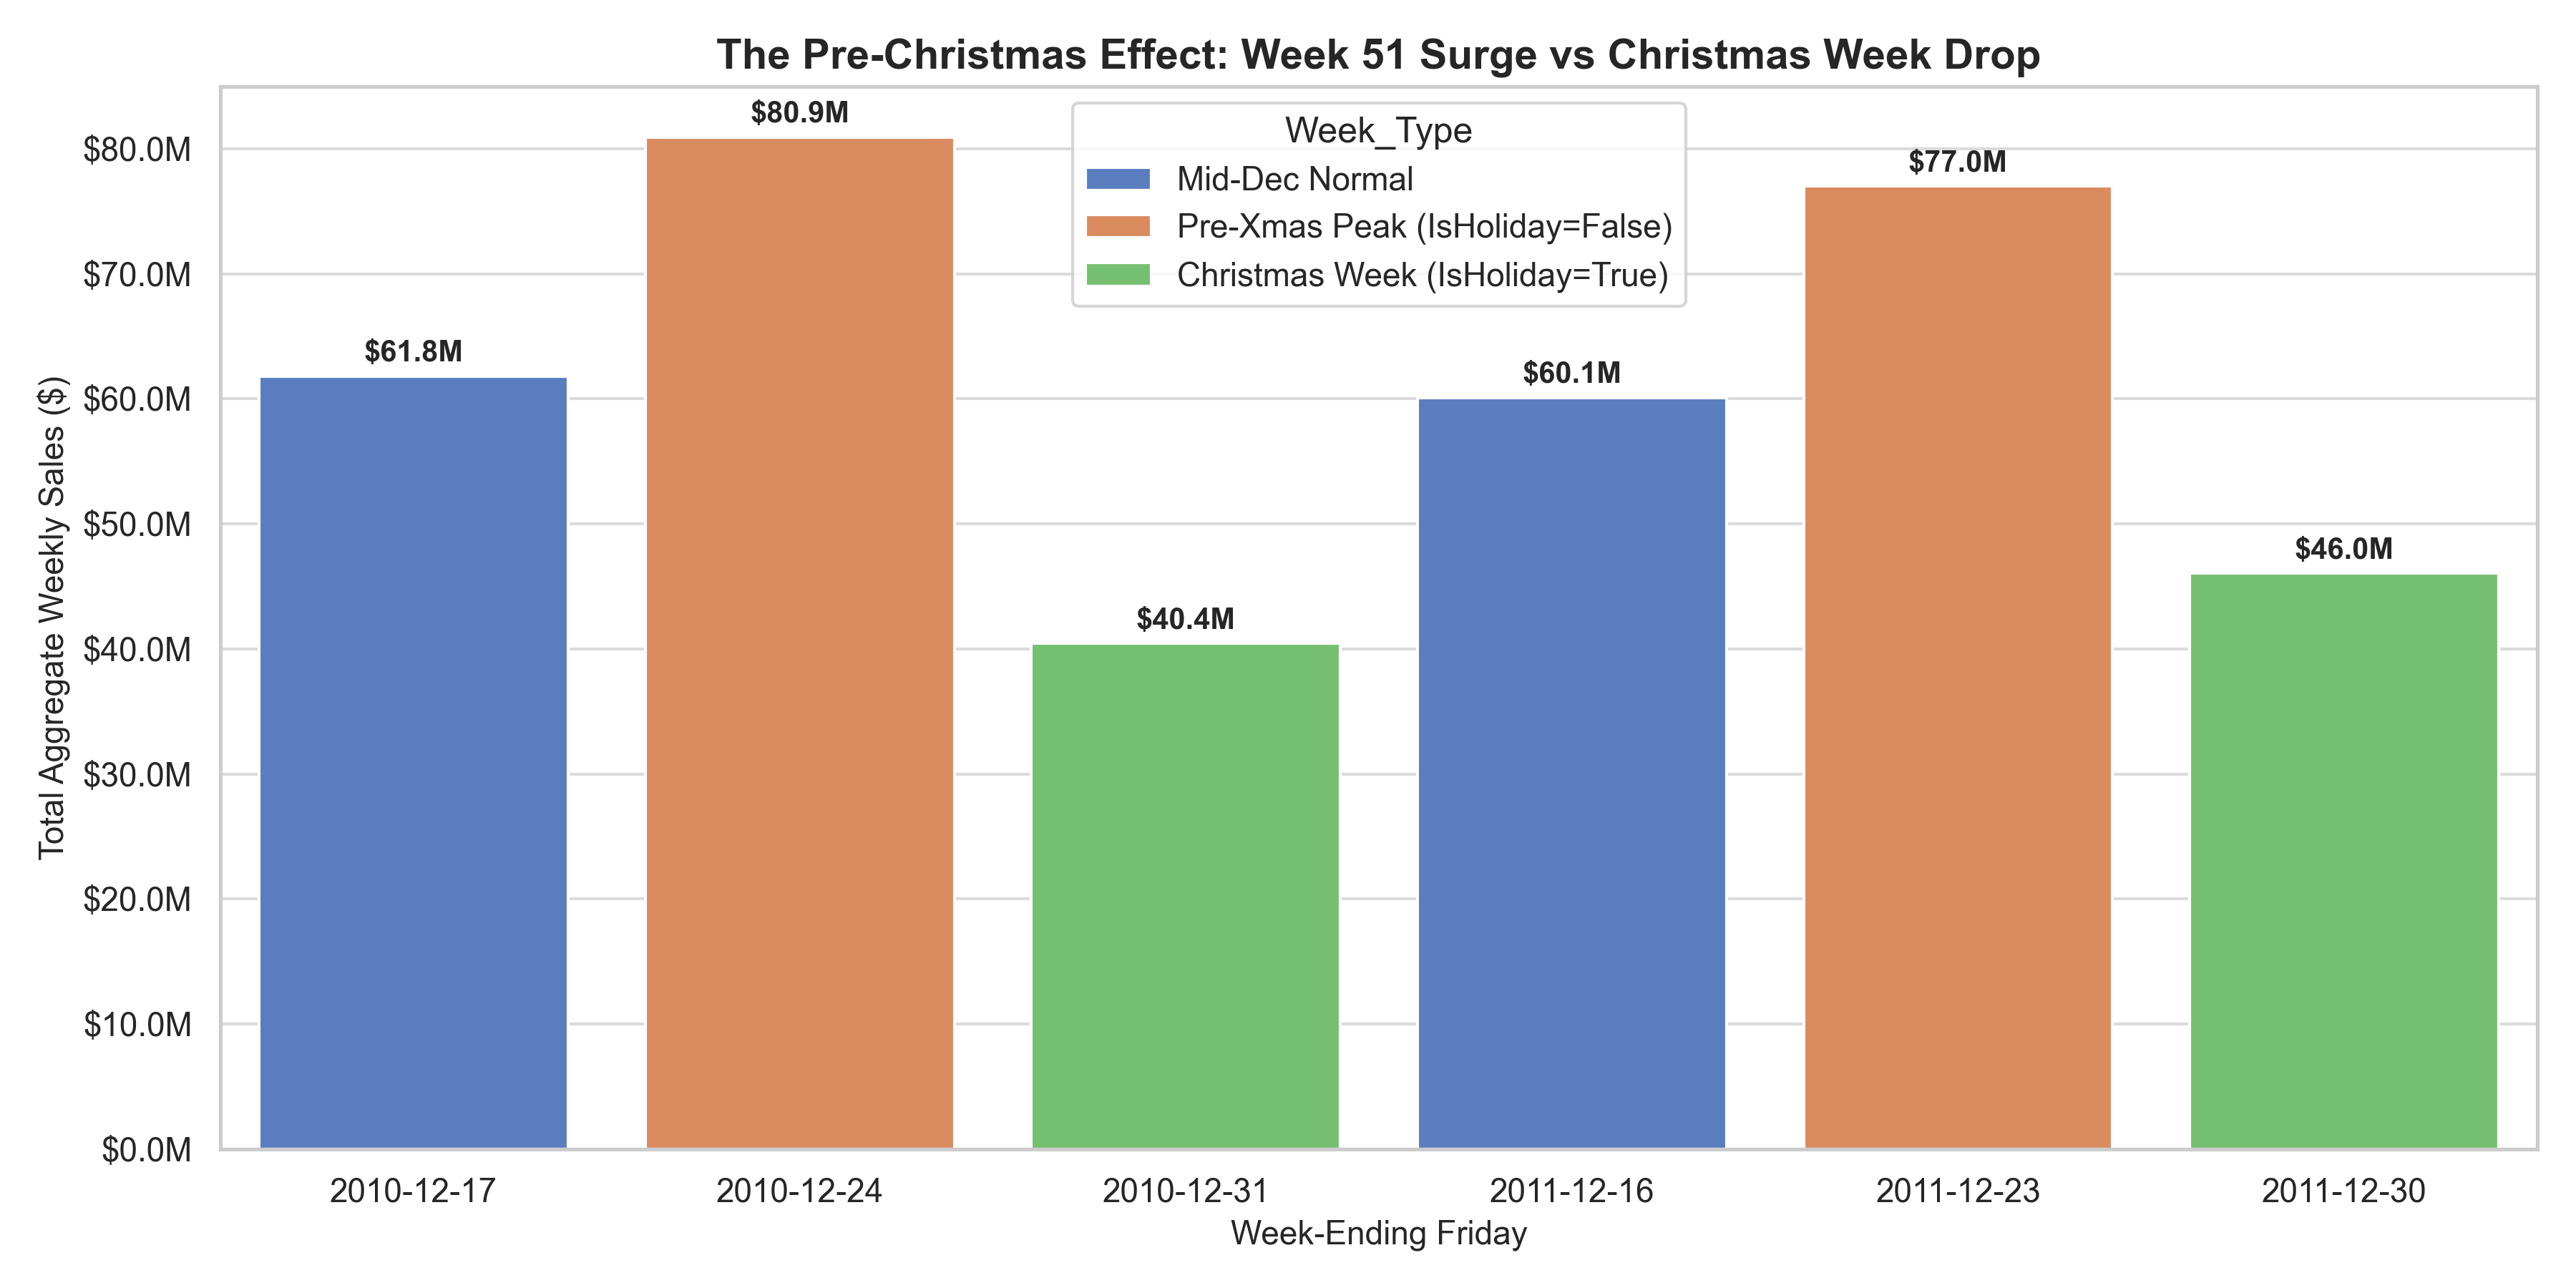

In [6]:
dec_dates = ["2010-12-17", "2010-12-24", "2010-12-31", "2011-12-16", "2011-12-23", "2011-12-30"]
dec_summary = train[train['Date'].dt.strftime('%Y-%m-%d').isin(dec_dates)].groupby('Date').agg({
    'Weekly_Sales': 'sum',
    'IsHoliday': 'first'
}).reset_index()
print(dec_summary)

display(Image(filename=os.path.join("..", "outputs", "figures", "fig13_pre_christmas_effect_analysis.png")))


## 6. Promotional MarkDowns & Macroeconomic Indicators

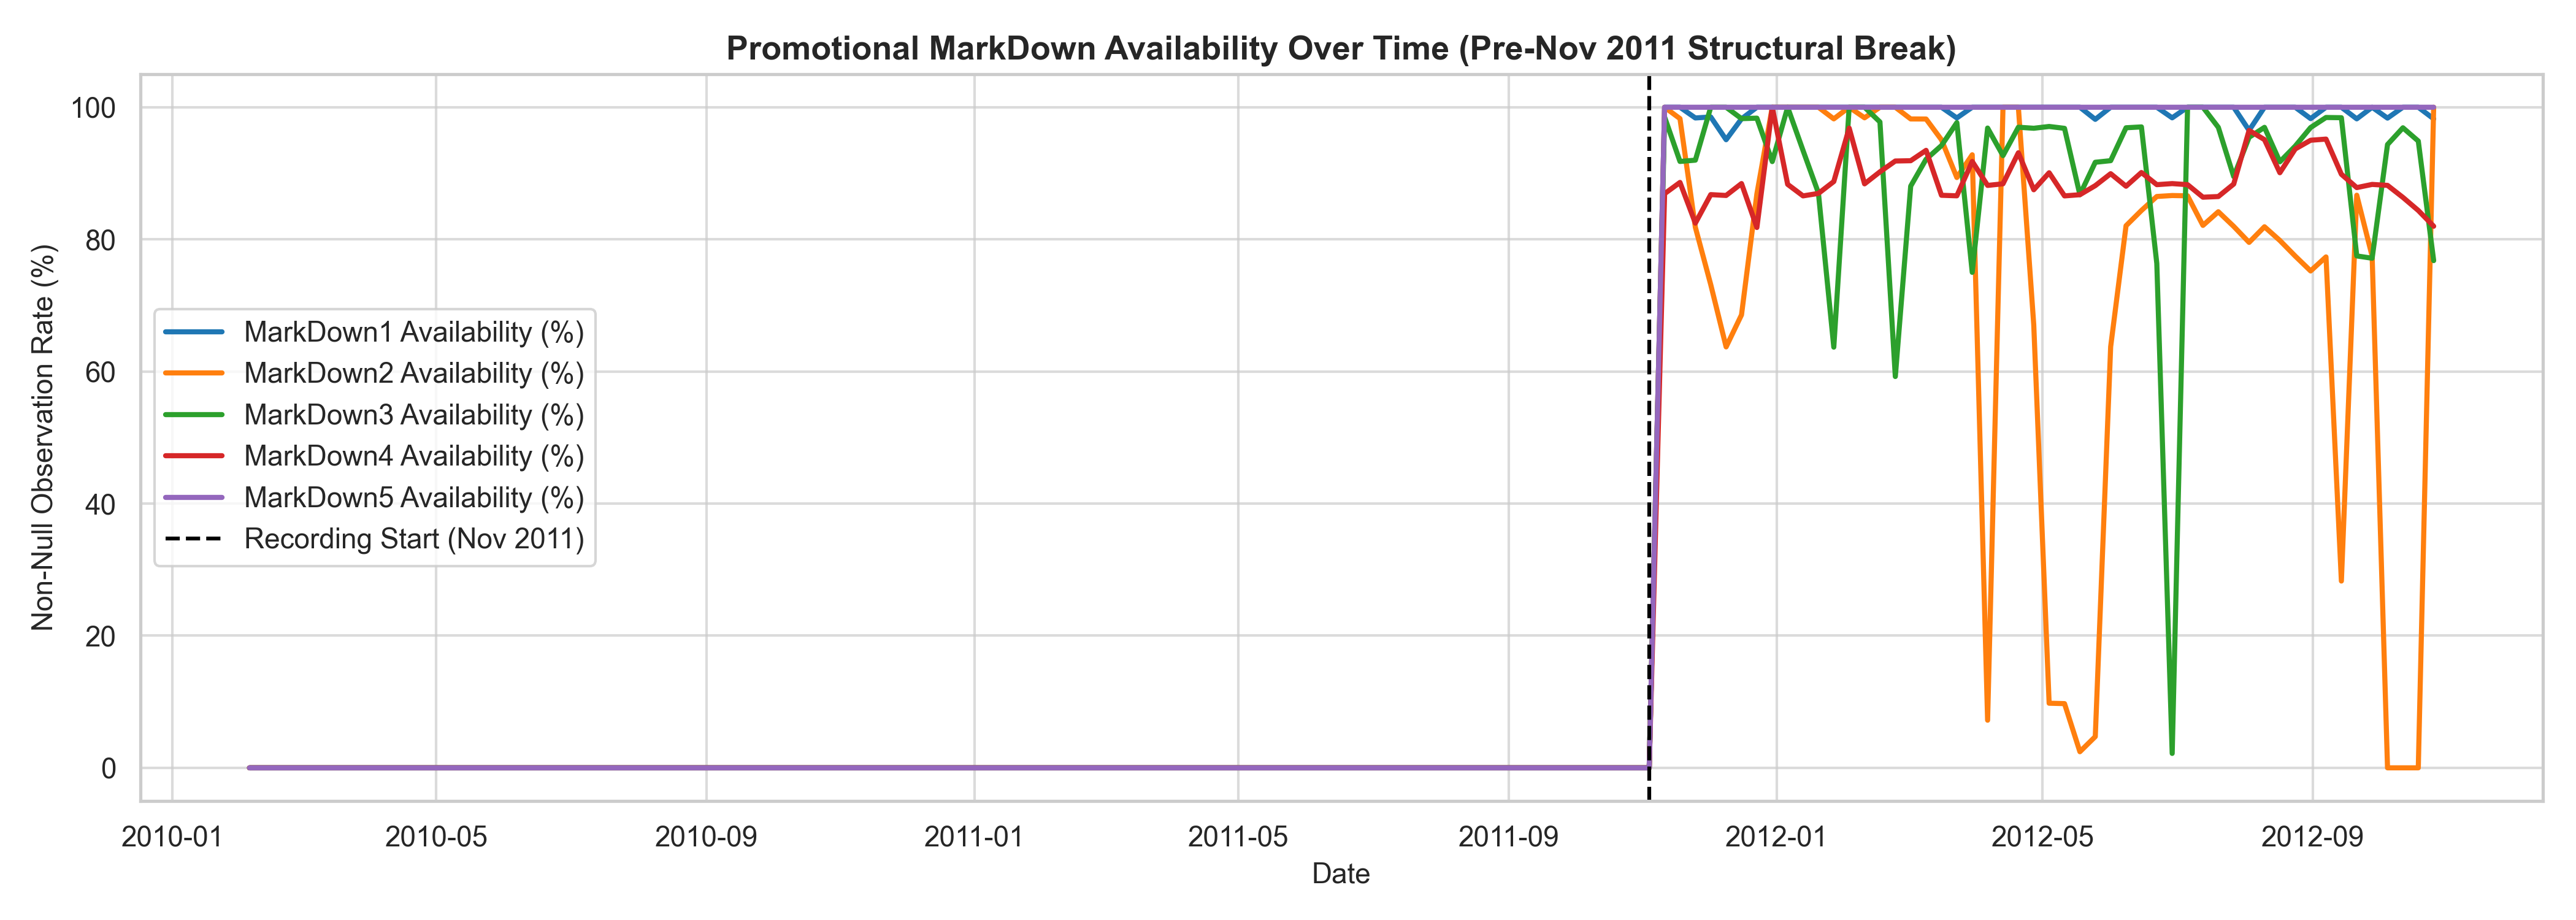

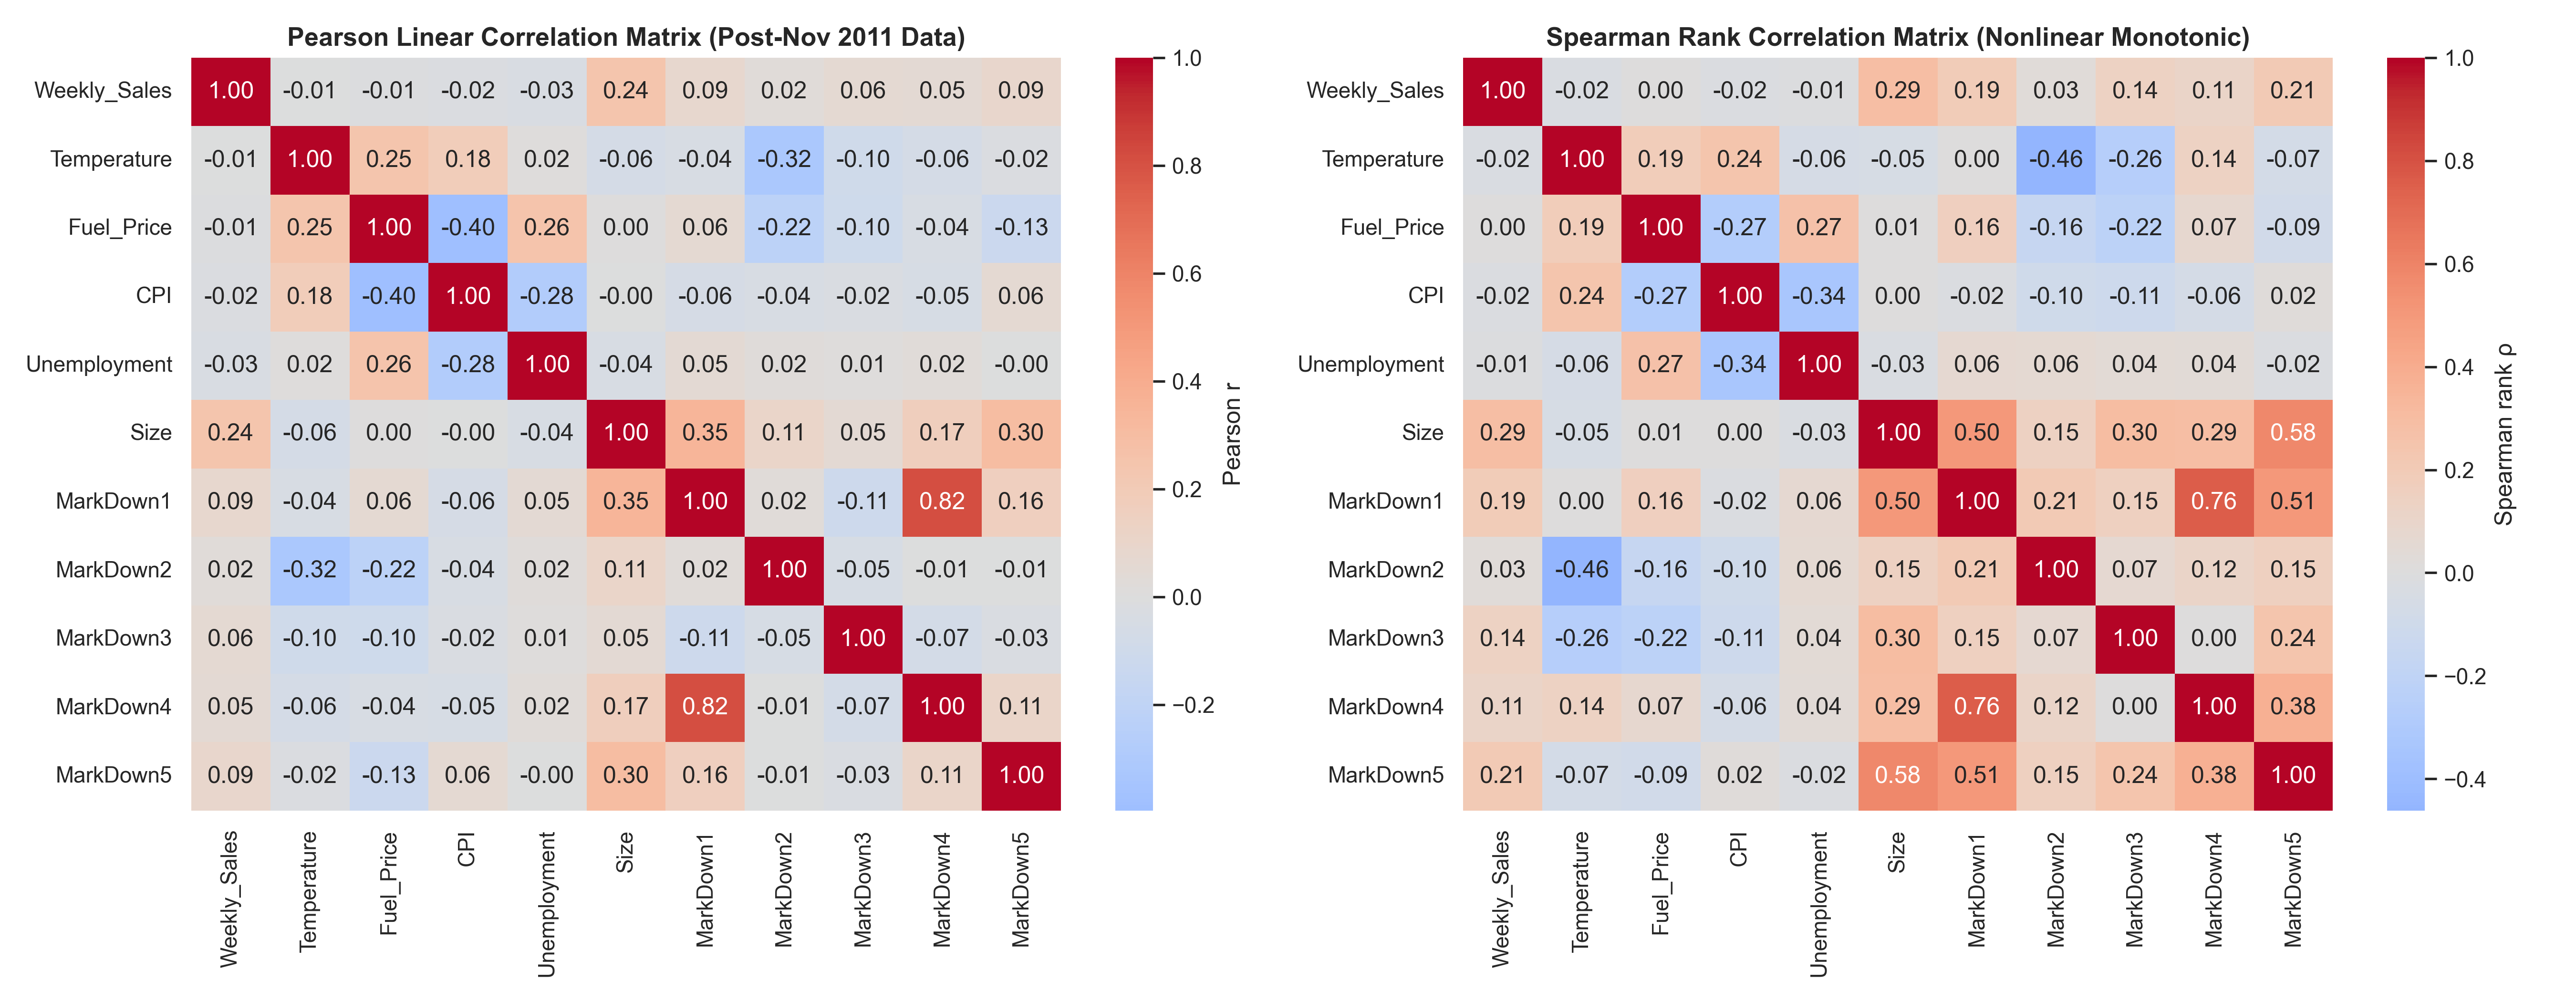

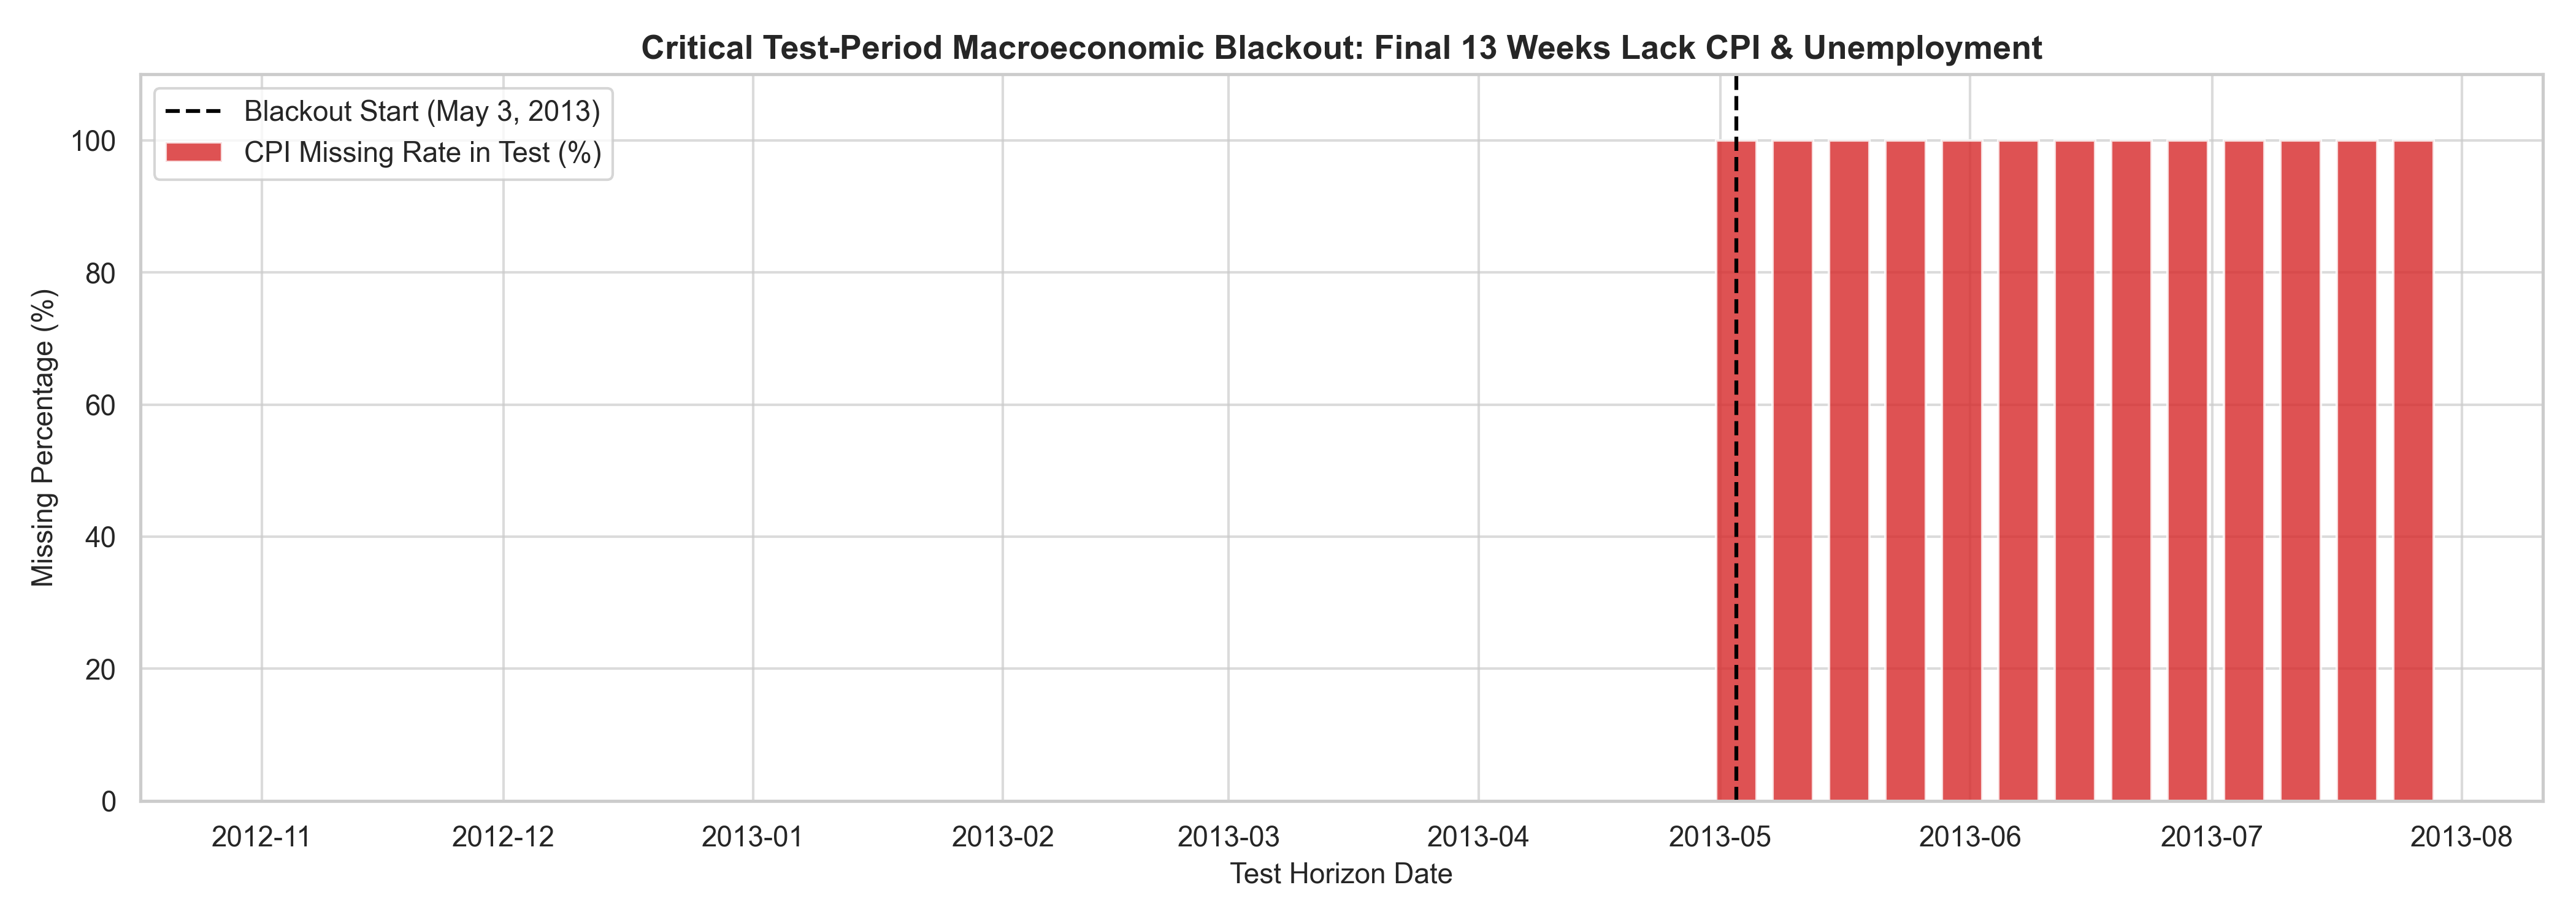

In [7]:
display(Image(filename=os.path.join("..", "outputs", "figures", "fig14_markdown_temporal_availability.png")))
display(Image(filename=os.path.join("..", "outputs", "figures", "fig15_economic_features_correlation_matrix.png")))
display(Image(filename=os.path.join("..", "outputs", "figures", "fig18_test_cpi_unemployment_blackout.png")))
